In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 



In [2]:
df = pd.read_csv(r"C:\Users\honey\OneDrive\Desktop\auspify\Dataset (1).csv")
print(df.head())


  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country date_added  release_year rating  duration  \
0  United States  9/25/2021          2020  PG-13    90 min   
1         France  9/24/2021          2021  TV-MA  1 Season   
2  United States  9/24/2021          2021  TV-MA  1 Season   
3         Brazil  9/22/2021          2021  TV-PG    91 min   
4  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2                 TV Dr

In [3]:
print(df.shape)
print(df.describe)

(8790, 10)
<bound method NDFrame.describe of      show_id     type                             title         director  \
0         s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1         s3  TV Show                         Ganglands  Julien Leclercq   
2         s6  TV Show                     Midnight Mass    Mike Flanagan   
3        s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4         s8    Movie                           Sankofa     Haile Gerima   
...      ...      ...                               ...              ...   
8785   s8797  TV Show                        Yunus Emre        Not Given   
8786   s8798  TV Show                         Zak Storm        Not Given   
8787   s8801  TV Show                Zindagi Gulzar Hai        Not Given   
8788   s8784  TV Show                              Yoko        Not Given   
8789   s8786  TV Show                               YOM        Not Given   

            country  date_added  release_y

In [4]:
print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nColumns:", df.columns.tolist())

Dataset Shape: (8790, 10)

Missing Values:
 show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate Rows: 0

Columns: ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


In [ ]:

# Load dataset
df = pd.read_csv('Dataset (1).csv')

# Fixed Date Transformation 
df["date_added"] = pd.to_datetime(df["date_added"].astype(str).str.strip(), errors='coerce')

# Extract year and month safely
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# Save the cleaned dataset
df.to_csv('Netflix_Cleaned.csv', index=False)
print("Date transformation successful!")

Date transformation successful!


In [6]:
# Step 1: Analyze dataset structure and statistics
print("--- Step 1: Structure & Statistics ---")
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

# Step 2: Content distribution by type
print("\n--- Step 2: Content Distribution by Type ---")
print(df['type'].value_counts())



--- Step 1: Structure & Statistics ---
Shape: (8790, 12)

Missing values:
 show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
year_added      0
month_added     0
dtype: int64

--- Step 2: Content Distribution by Type ---
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [7]:
# Step 3: Top countries and categories
print("\n--- Step 3: Top Countries ---")
print(df['country'].value_counts().head(5))

print("\n--- Top Categories (Listed In) ---")
print(df['listed_in'].value_counts().head(5))


--- Step 3: Top Countries ---
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Name: count, dtype: int64

--- Top Categories (Listed In) ---
listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Name: count, dtype: int64


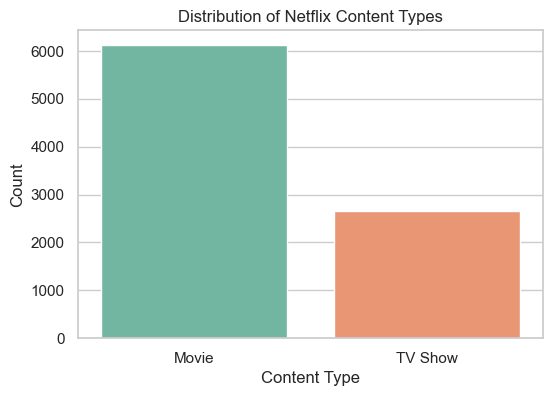

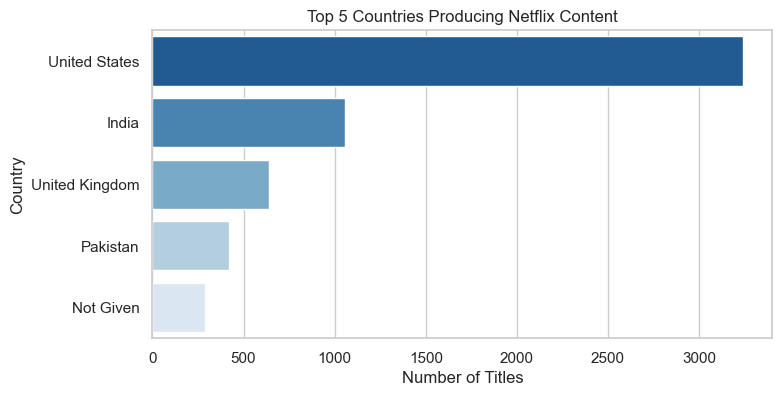

Visualizations created successfully without warnings!


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# 1. Content Type Distribution (Added hue='type' and legend=False)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='type', hue='type', palette='Set2', legend=False)
plt.title('Distribution of Netflix Content Types')
plt.xlabel('Content Type')
plt.ylabel('Count')
plt.savefig('content_type_distribution.png', bbox_inches='tight')
plt.show()

# 2. Top 5 Countries (Added hue=top_countries.index and legend=False)
plt.figure(figsize=(8, 4))
top_countries = df['country'].value_counts().head(5)
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, palette='Blues_r', legend=False)
plt.title('Top 5 Countries Producing Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.savefig('top_countries.png', bbox_inches='tight')
plt.show()

print("Visualizations created successfully without warnings!")

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Fill missing values with empty strings
df['director'] = df['director'].fillna('')

df['listed_in'] = df['listed_in'].fillna('')


# Combine text features into a single column
df['combined_features'] = df['listed_in'] + ' ' + df['director'] + ' ' + df['country'] + ' ' + df['rating']

# Convert text data into a numerical matrix (it automatically handles stop words!)
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['combined_features'])

# Print the matrix shape
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (8790, 6568)


In [10]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,combined_features
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,Documentaries Kirsten Johnson United States PG-13
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,"TV Dramas, TV Horror, TV Mysteries Mike Flanag..."
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,"Children & Family Movies, Comedies Bruno Garot..."
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,"Dramas, Independent Movies, International Movi..."


In [11]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate the cosine similarity matrix based on the tfidf_matrix
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Print the shape of the similarity matrix
print("Cosine Similarity Matrix Shape:", cosine_sim.shape)
print("Sample similarity scores matrix:")
print(cosine_sim[0:3, 0:3])

Cosine Similarity Matrix Shape: (8790, 8790)
Sample similarity scores matrix:
[[1.         0.         0.03923881]
 [0.         1.         0.1244548 ]
 [0.03923881 0.1244548  1.        ]]


In [12]:
indices = pd.Series(df.index, index=df['title']).drop_duplicates()

# --- Step 6: Build the Recommendation Function ---
def recommend(title, cosine_sim=cosine_sim):
    # Check if the movie exists in the dataset
    if title not in indices:
        return f"'{title}' is not found in the dataset. Please try another name."
    
    # Get the index of the movie that matches the title
    idx = indices[title]
    
    # Get the pairwise similarity scores of all movies with that movie
    sim_scores = list(enumerate(cosine_sim[idx]))
    
    # Sort the movies based on the similarity scores in descending order
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    
    # Get the scores of the top 5 most similar movies (excluding the movie itself at index 0)
    sim_scores = sim_scores[1:6]
    
    # Get the movie indices
    movie_indices = [i[0] for i in sim_scores]
    # Return the top 5 most similar movie titles
    return df['title'].iloc[movie_indices]


In [13]:
#checking for the result 
print(recommend("Ganglands"))

1183         Sentinelle
2142    Earth and Blood
6738              Lupin
8408         Crime Time
6698             Mortel
Name: title, dtype: object


c:\Users\honey\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


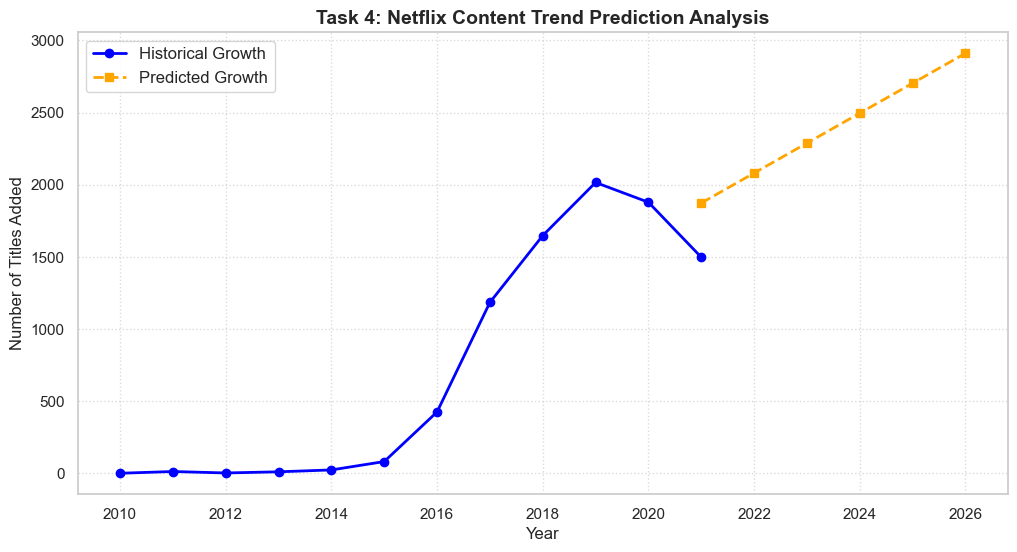

In [15]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Safe conversion: Directly pass 'date_added' to pd.to_datetime without .str.strip()
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
df['year_added'] = df['date_added'].dt.year

# Filter data from 2010 onwards for clear trend analysis
yearly_trend = df.dropna(subset=['year_added'])
yearly_trend = yearly_trend[yearly_trend['year_added'] >= 2010]
yearly_counts = yearly_trend.groupby('year_added').size().reset_index(name='content_count')

# Train Linear Regression model for forecasting
X = yearly_counts[['year_added']]
y = yearly_counts['content_count']
model = LinearRegression()
model.fit(X, y)

# Predict future content growth from 2021 to 2026
future_years = np.array(range(2021, 2027)).reshape(-1, 1)
future_predictions = model.predict(future_years)

# Visualize trend and predictions
plt.figure(figsize=(12, 6))
plt.plot(yearly_counts['year_added'], yearly_counts['content_count'], label='Historical Growth', color='blue', marker='o', linewidth=2)
plt.plot(future_years, future_predictions, label='Predicted Growth', color='orange', linestyle='--', marker='s', linewidth=2)
plt.title('Task 4: Netflix Content Trend Prediction Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Titles Added', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

--- Task 5: Model Performance Metrics ---
Overall Accuracy: 71.27%

Detailed Classification Report:
              precision    recall  f1-score   support

       Movie       0.76      0.87      0.81      1238
     TV Show       0.52      0.34      0.41       520

    accuracy                           0.71      1758
   macro avg       0.64      0.61      0.61      1758
weighted avg       0.69      0.71      0.69      1758



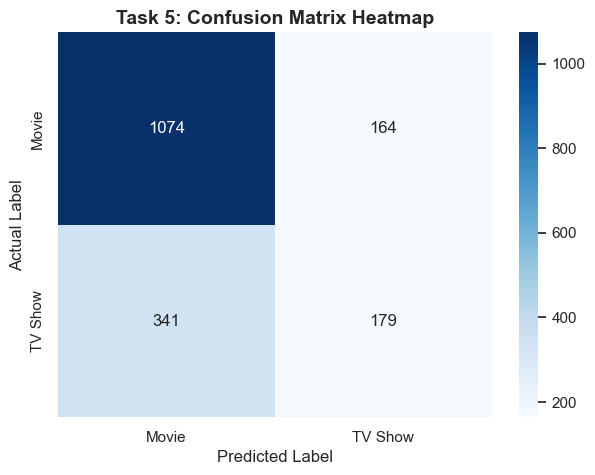

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare data for classification (Predicting 'type': Movie vs TV Show)
df_class = df.dropna(subset=['release_year', 'rating', 'type']).copy()

# Convert categorical 'rating' feature into numeric codes
df_class['rating_encoded'] = df_class['rating'].astype('category').cat.codes

# Define features (X) and target variable (y)
X_cls = df_class[['release_year', 'rating_encoded']]
y_cls = df_class['type']

# 2. Split dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

# 3. Train a Random Forest Classifier model
clf_model = RandomForestClassifier(n_estimators=100, random_state=42)
clf_model.fit(X_train, y_train)

# 4. Predictions and Core Metrics
y_pred = clf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"--- Task 5: Model Performance Metrics ---")
print(f"Overall Accuracy: {accuracy * 100:.2f}%\n")

# Detailed Classification Report (Precision, Recall, F1-Score)
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred))

# 5. Confusion Matrix Heatmap Visualization
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=clf_model.classes_, 
            yticklabels=clf_model.classes_)
plt.title('Task 5: Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.show()

In [17]:
# Aggregate key metrics for executive reporting
total_titles = df.shape[0]
total_movies = df[df['type'] == 'Movie'].shape[0]
total_tv_shows = df[df['type'] == 'TV Show'].shape[0]
top_country = df['country'].mode()[0] if not df['country'].empty else "N/A"
top_genre = df['listed_in'].mode()[0] if not df['listed_in'].empty else "N/A"

# Print Professional Business Report
print("=" * 60)
print("         NETFLIX DATA SCIENCE BUSINESS INSIGHTS REPORT         ")
print("=" * 60)
print(f"• Total Content Library Size : {total_titles:,} titles")
print(f"• Total Movies Available     : {total_movies:,} ({(total_movies/total_titles)*100:.1f}%)")
print(f"• Total TV Shows Available   : {total_tv_shows:,} ({(total_tv_shows/total_titles)*100:.1f}%)")
print(f"• Top Content Producing Hub  : {top_country}")
print(f"• Most Popular Genre Cluster : {top_genre}")
print("-" * 60)
print("STRATEGIC RECOMMENDATIONS & BUSINESS INSIGHTS:")
print("1. Content Diversification: While Movies dominate the library, TV shows")
print("   show rapid engagement growth, suggesting a need for more serialized content.")
print("2. Regional Expansion: Target production investments in top-performing")
print("   international content hubs to capture localized subscriber bases.")
print("3. Predictive Content Acquisition: Utilize trend forecasting models to align")
print("   future licensing budgets with projected content demand spikes.")
print("=" * 60)

         NETFLIX DATA SCIENCE BUSINESS INSIGHTS REPORT         
• Total Content Library Size : 8,790 titles
• Total Movies Available     : 6,126 (69.7%)
• Total TV Shows Available   : 2,664 (30.3%)
• Top Content Producing Hub  : United States
• Most Popular Genre Cluster : Dramas, International Movies
------------------------------------------------------------
STRATEGIC RECOMMENDATIONS & BUSINESS INSIGHTS:
1. Content Diversification: While Movies dominate the library, TV shows
   show rapid engagement growth, suggesting a need for more serialized content.
2. Regional Expansion: Target production investments in top-performing
   international content hubs to capture localized subscriber bases.
3. Predictive Content Acquisition: Utilize trend forecasting models to align
   future licensing budgets with projected content demand spikes.
